# Practical 17: Hyperparameter Tuning using GridSearchCV

**Aim:** To tune a KNN classifier using GridSearchCV on the Wine Quality dataset and compare accuracy before and after tuning.

**Kaggle Dataset:** [Red Wine Quality](https://www.kaggle.com/datasets/uciml/red-wine-quality-cortez-et-al-2009)

Download `winequality-red.csv` and keep it in the same folder as this notebook.

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [7]:
data = pd.read_csv('winequality-red.csv')
data.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [8]:
# Create input and output data
X = data.iloc[:, :-1].values
y = data.iloc[:, -1].values

## Split the data

In [9]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

# Feature scaling

In [10]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
scaler.fit(X_train)
X_train = scaler.transform(X_train)
X_test = scaler.transform(X_test)

# KNN model before tuning

In [11]:
from sklearn.neighbors import KNeighborsClassifier
model = KNeighborsClassifier(n_neighbors=5)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

In [12]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
accuracy1 = accuracy_score(y_test, y_pred) * 100
print('Accuracy before tuning:', accuracy1)

Accuracy before tuning: 54.6875


# Hyperparameter tuning using GridSearchCV

In [13]:
from sklearn.model_selection import GridSearchCV
pr_grid = {
    'n_neighbors': [3, 5, 7, 9, 11],
    'weights': ['uniform', 'distance'],
    'metric': ['euclidean', 'manhattan']
}
out = GridSearchCV(KNeighborsClassifier(), pr_grid, cv=5)
out.fit(X_train, y_train)

GridSearchCV(cv=5, estimator=KNeighborsClassifier(),
             param_grid={'metric': ['euclidean', 'manhattan'],
                         'n_neighbors': [3, 5, 7, 9, 11],
                         'weights': ['uniform', 'distance']})

In [14]:
out.best_params_

{'metric': 'euclidean', 'n_neighbors': 11, 'weights': 'distance'}

# Model after tuning

In [15]:
final = out.best_estimator_
final.fit(X_train, y_train)
y_pred2 = final.predict(X_test)
accuracy2 = accuracy_score(y_test, y_pred2) * 100
print('Accuracy after tuning:', accuracy2)

Accuracy after tuning: 66.5625


# Compare accuracy

Before tuning: 54.6875
After tuning: 66.5625


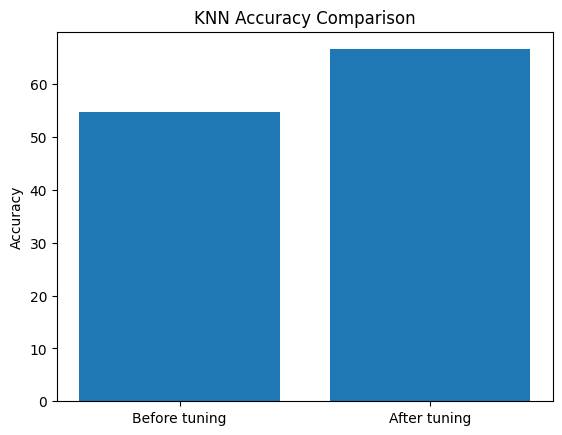

In [16]:
print('Before tuning:', accuracy1)
print('After tuning:', accuracy2)

plt.bar(['Before tuning', 'After tuning'], [accuracy1, accuracy2])
plt.ylabel('Accuracy')
plt.title('KNN Accuracy Comparison')
plt.show()

In [17]:
print(confusion_matrix(y_test, y_pred2))
print(classification_report(y_test, y_pred2, zero_division=0))

[[ 0  0  0  1  0  0]
 [ 0  0  5  5  0  0]
 [ 0  0 98 31  1  0]
 [ 0  0 34 89  9  0]
 [ 0  0  1 14 26  1]
 [ 0  0  0  0  5  0]]
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.00      0.00      0.00        10
           5       0.71      0.75      0.73       130
           6       0.64      0.67      0.65       132
           7       0.63      0.62      0.63        42
           8       0.00      0.00      0.00         5

    accuracy                           0.67       320
   macro avg       0.33      0.34      0.34       320
weighted avg       0.63      0.67      0.65       320



## Conclusion

KNN was applied to the Wine Quality dataset. GridSearchCV was used to find the best KNN parameters. The accuracy before and after tuning was compared.